# Apresentação
## A Matemática por Trás do Monopoly: Cadeias de Markov e o Método da Potência

**Nome:** Maria Carolina Boudreaux Ramirez Deleito

---

### Ideia
A ideia inicial surgiu da questão E9 da lista de modelos dinâmicos do professor João Paixão: um tabuleiro pequeno, de 8 casas, com uma casa "volte 2 casas" e outra "avance 1 casa", em que se pergunta qual é a casa mais provável de terminar uma rodada.

Em que me veio o pensamento, podemos calcular a probabilidade de cair em cada casa, se aplicarmos a ideia a um tabuleiro maior, de um jogo comum, como monopoly, teremos um "hack" para quais são as casas mais prováveis de se cair em uma partida, e, subsequentemente, quais são melhores de serem comprados.

Encontrei então o vídeo *"The Mathematics of Winning Monopoly"*, do canal Stand-up Maths (Matt Parker com Hannah Fry), e no capítulo homônimo do livro *The Indisputable Existence of Santa Claus*, de Hannah Fry e Thomas Oleron Evans, que me forneceu um embasamento melhor para usar como ponto de partida (recomendo muitíssimo o vídeo).

Teremos então o tabuleiro de Monopoly (40 casas) modelado como uma **Cadeia de Markov homogênea no tempo** em que cada casa é um "estado" e a cada turno, o jogador se move de acordo com uma distribuição de probabilidade que depende **somente** da casa atual (propriedade de Markov), sem importar como chegamos ali.

Uma observação importante, poderia ter construído esse trabalho de forma bem mais sucinta  apenas com os temas de COCADA, que era minha ideia inicial, retirando os elementos que "fogem" dos assuntos (como regras especiais e estratégias de jogo baseadas em preço), mas acabei por me divertir brincando com probabilidades e matrizes, espero que você, como leitor, se divirta também!

### Temas abordados

- **Autovalores e autovetores na prática**: a distribuição de equilíbrio de longo prazo é o autovetor dominante associado ao autovalor $\lambda = 1$.
- **Método da Potência**: algoritmo iterativo $v^{(k+1)} = A v^{(k)}$ para encontrar o autovetor dominante sem calcular autovalores explicitamente.
- **Método da Potência Inversa**: encontra autovalores específicos (aqui, o segundo maior em módulo) resolvendo sistemas lineares $(A - \mu I) w = v$ a cada iteração.
- **Validação por Monte Carlo** (extensão para o portfólio): compara a matriz com uma simulação das regras completas.
- **Retorno financeiro** (extensão para o portfólio): cruza a frequência de visita com os aluguéis.

### Convenção adotada

$$v^{(k+1)} = A v^{(k)}$$

onde $v$ é um vetor-coluna de probabilidades (soma = 1) e $A$ é uma matriz **coluna-estocástica** (cada coluna soma 1). A entrada $A_{i,j}$ é a probabilidade de, estando na casa $j$, o jogador terminar o próximo turno na casa $i$.

Isso equivale à transposta da matriz de transição $P$ do Markov "clássico" (onde $P_{i,j} = P(\text{próximo}=j \mid \text{atual}=i)$, linha-estocástica). Construímos $P$ primeiro (mais intuitivo) e depois definimos $A = P^T$.

---

### Referências:
Manual de Regras Monopoly: https://bglitoralalentejano.wordpress.com/wp-content/uploads/2015/11/monopoly.pdf

"The Mathematics of Winning Monopoly": https://www.youtube.com/watch?v=ubQXz5RBBtU

"Monopoly: The Mathematical Secret Behind Winning": https://www.youtube.com/watch?v=8FP8Owdt2WY

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from monopoly.tabuleiro import *
from monopoly.transicao import *
from monopoly.metodos import metodo_da_potencia, metodo_potencia_inversa
from monopoly.simulacao import simular, PRESO
from monopoly.economia import retorno_por_grupo

np.set_printoptions(precision=4, suppress=True, linewidth=140)

> O código das regras está no pacote [`monopoly/`](monopoly/). Aqui ficam a narrativa e as verificações de cada passo.

# Parte 1 - Definição do espaço de estados (40 casas do tabuleiro)
Queremos modelar as 40 casas do tabuleiro de forma matricial.

(Obs: acabei optando por usar a versão Monopoly estadunidense traduzida para o português, mas poderíamos mudar a análise para qualquer variação de Monopoly/Jogo da Vida apenas mudando o nome das casas)

In [2]:
print(f"Número de estados (casas do tabuleiro): {N}")
print(f"Casa 0  = '{NOMES[0]}'")
print(f"Casa 10 = '{NOMES[10]}'")
print(f"Casa 30 = '{NOMES[30]}'  (manda o jogador direto para a casa 10)")
print(f"Casas de Sorte:             {SORTE_IDX}")
print(f"Casas de Cofre Comunitário: {COFRE_IDX}")
print(f"Ferrovias:  {FERROVIAS}")
print(f"Utilidades: {UTILIDADES}")

Número de estados (casas do tabuleiro): 40
Casa 0  = 'Partida (GO)'
Casa 10 = 'Cadeia / Só Visitando'
Casa 30 = 'Va para a Cadeia'  (manda o jogador direto para a casa 10)
Casas de Sorte:             [7, 22, 36]
Casas de Cofre Comunitário: [2, 17, 33]
Ferrovias:  [5, 15, 25, 35]
Utilidades: [12, 28]


# Parte 2 - Construção da Matriz de Transição
Queremos agora implementar as regras de jogo para mapear todas as possíveis movimentações, por dados e regras de jogo

#### 2.1 Movimentação Básica: Soma de dois dados (2 a 12)

Soma | Probabilidade
  2  | 0.0278
  3  | 0.0556
  4  | 0.0833
  5  | 0.1111
  6  | 0.1389
  7  | 0.1667
  8  | 0.1389
  9  | 0.1111
 10  | 0.0833
 11  | 0.0556
 12  | 0.0278

Soma das probabilidades: 1.000000
7 é a soma mais provável (6/36), seguida por 6 e 8 (5/36 cada).
Todas as linhas somam 1? True


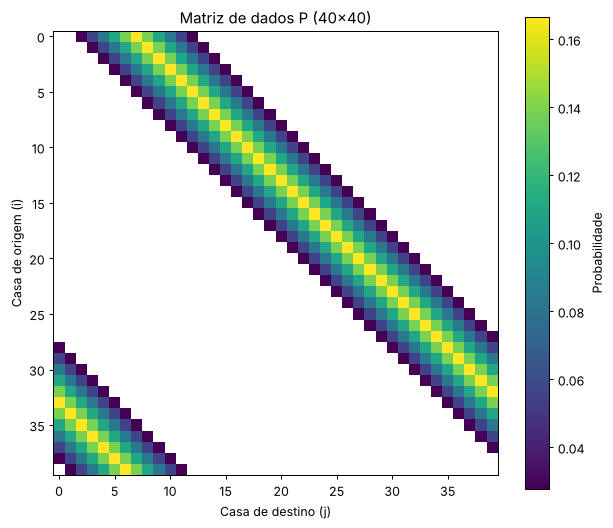

In [3]:
prob_soma = probabilidades_dois_dados()
print("Soma | Probabilidade")
for s in range(2, 13):
    print(f" {s:2d}  | {prob_soma[s]:.4f}")
print(f"\nSoma das probabilidades: {sum(prob_soma.values()):.6f}")
print("7 é a soma mais provável (6/36), seguida por 6 e 8 (5/36 cada).")

P = matriz_dados()
print(f"Todas as linhas somam 1? {np.allclose(P.sum(axis=1), 1.0)}")

plt.figure(figsize=(7, 6))
im = plt.imshow(np.where(P > 0, P, np.nan), cmap="viridis")
plt.colorbar(im, label="Probabilidade")
plt.xlabel("Casa de destino (j)")
plt.ylabel("Casa de origem (i)")
plt.title("Matriz de dados P (40x40)")
plt.xticks(range(0, N, 5))
plt.yticks(range(0, N, 5))
plt.tight_layout()
plt.show()

Obs: o print dos valores de uma matriz 40x40 não aparecia de forma clara no Colab, então inicialmente deixei apenas uma foto da matriz. Depois de um comentário do monitor durante a apresentação de sexta, de que gostaria de ver as demais matrizes, mudei para um mapa de calor: quanto mais próximo de amarelo, maior a probabilidade; quanto mais próximo de roxo, menor. Essa escala é usada nos demais gráficos de matriz.

#### 2.2 Regra Especial: "Vá para a Cadeia"
Toda vez que o dado levaria o jogador exatamente a casa 30, ele é redirecionado imediatamente para a casa 10 (Cadeia). Além disso, a própria casa 30 nunca fica "ocupada", de lá, vai-se para a cadeia com probabilidade 1.

In [4]:
P_v2 = aplica_va_para_cadeia(P)
print(f"Coluna 30 após a correção: soma = {P_v2[:, VA_PARA_CADEIA].sum():.6f}")
print(f"Linhas ainda somam 1? {np.allclose(P_v2.sum(axis=1), 1.0)}")

Coluna 30 após a correção: soma = 0.000000
Linhas ainda somam 1? True


#### 2.3 Regra Especial: Cartas de Sorte
Das 16 cartas de Sorte, 10 movem o jogador para uma casa específica:
"Avance ao Ponto de Partida, Avenida Illinois, Praça St. Charles, Ferrovia mais proxima (2 cartas), Companhia mais proxima, Volte 3 casas, Vá para a Cadeia, Reading Railroad, Boardwalk". As outras 6 cartas não movem o jogador (pagamentos, sai-da-cadeia-gratis etc).
Como a ferrovia/companhia 'mais proxima' depende de onde esta a casa de Sorte, tratamos cada uma das 3 casas de Sorte (7, 22, 36) separadamente.

In [5]:
for c in SORTE_IDX:
    print(f"Sorte na casa {c}: destinos {destinos_sorte(c)}")

P_v3 = aplica_regra_sorte(P_v2)
print(f"\nLinhas ainda somam 1 após a regra de Sorte? {np.allclose(P_v3.sum(axis=1), 1.0)}")

Sorte na casa 7: destinos [0, 24, 11, 12, 15, 15, 4, 10, 5, 39]
Sorte na casa 22: destinos [0, 24, 11, 28, 25, 25, 19, 10, 5, 39]
Sorte na casa 36: destinos [0, 24, 11, 12, 5, 5, 33, 10, 5, 39]

Linhas ainda somam 1 após a regra de Sorte? True


#### 2.4 Regra Especial: Cartas de Cofre Comunitário
Das 16 cartas de Cofre, apenas 2 movem o jogador: 'Avance ao Ponto de Partida' e 'Vá para a Cadeia'. As outras 14 são pagamentos/recebimentos que não alteram a posição no tabuleiro.

In [6]:
P_v4 = aplica_regra_cofre(P_v3)
print(f"Linhas ainda somam 1 após a regra de Cofre? {np.allclose(P_v4.sum(axis=1), 1.0)}")

Linhas ainda somam 1 após a regra de Cofre? True


#### 2.5 Efeito Médio de Dados Duplos Repetidos (3x seguidas = cadeia)
Tirar a mesma face nos dois dados tem probabilidade 1/6, tirar isso três vezes seguidas tem probabilidade (1/6)³, e isso pode acontecer a cada 3 lances,  então definimos um pequeno incremento médio epsilon a ser somado a probabilidade de ir para a cadeia, **a partir de qualquer casa**, e depois re-normalizamos a linha inteira para continuar somando 1.
Obs: Sim! Isso é uma regra do monopoly

In [7]:
print(f"epsilon = (1/6)^3 / 3 = {EPSILON_DUPLOS:.6f}")
P_final = aplica_duplos(P_v4)
print(f"Linhas ainda somam 1 após o efeito de duplos? {np.allclose(P_final.sum(axis=1), 1.0)}")

epsilon = (1/6)^3 / 3 = 0.001543
Linhas ainda somam 1 após o efeito de duplos? True


#### 2.6 Normalização final e definição de A (coluna-estocástica)

$P$ é a matriz de transição "clássica" de Markov, onde:

$$P_{i,j} = P(\text{próximo}=j \mid \text{atual}=i)$$

e toda **linha** é estocástica (cada linha soma 1). O enunciado do projeto pede uma matriz $A$ **coluna-estocástica** para a fórmula

$$v^{(k+1)} = A\, v^{(k)}$$

com $v$ vetor-coluna.

Fazemos $A = P^T$ (transposta): $A_{i,j} = P_{j,i} = P(\text{atual}=j \rightarrow \text{próximo}=i)$.

Uma matriz coluna-estocástica sempre possui autovalor $\lambda = 1$, pois o vetor-linha de uns $(1,1,\dots,1)$ é autovetor à esquerda: $\mathbf{1}^T A = \mathbf{1}^T$, o que força $A$ a ter $\lambda=1$ como autovalor.

Um detalhe: a casa 30 nunca é ocupada, então ela é um estado transiente e a matriz completa não é irredutível. As outras 39 casas formam uma única classe recorrente e aperiódica; é nela que Perron-Frobenius garante a unicidade da distribuição estacionária.

Todas as colunas somam 1? True
Dimensão final de A: (40, 40)


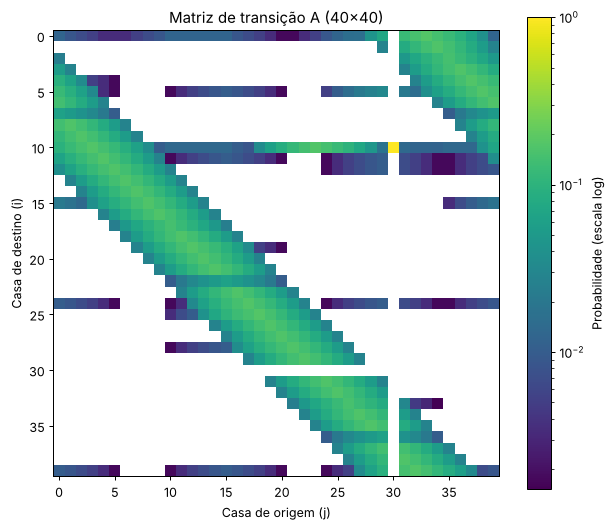

In [8]:
A = matriz_coluna_estocastica(P_final)
print(f"Todas as colunas somam 1? {np.allclose(A.sum(axis=0), 1.0)}")
print(f"Dimensão final de A: {A.shape}")

plt.figure(figsize=(7, 6))
im = plt.imshow(np.where(A > 0, A, np.nan), cmap="viridis", norm=matplotlib.colors.LogNorm())
plt.colorbar(im, label="Probabilidade (escala log)")
plt.xlabel("Casa de origem (j)")
plt.ylabel("Casa de destino (i)")
plt.title("Matriz de transição A (40x40)")
plt.xticks(range(0, N, 5))
plt.yticks(range(0, N, 5))
plt.tight_layout()
plt.show()

# Parte 3 - Método da Potência

Ideia: para quase qualquer vetor inicial

$$v^{(0)}$$

A sequência:
$$v^{(k)} = A^k v^{(0)}$$

 converge para o autovetor dominante de $A$ (associado ao maior autovalor em módulo). Como $A$ é coluna-estocástica e tem uma única classe recorrente aperiódica, esse autovalor dominante é exatamente $\lambda = 1$, e o autovetor correspondente, normalizado para somar 1, é a **distribuição estacionária** do jogo.

In [9]:
v0_go = np.zeros(N)
v0_go[GO] = 1.0
v0_uniforme = np.ones(N) / N

v_estacionario, iters_go, erros_go = metodo_da_potencia(A, v0_go)
v_unif, iters_unif, _ = metodo_da_potencia(A, v0_uniforme)

for k in [1, 2, 3, 25, 50, 100, iters_go]:
    print(f"iteração {k:4d}  |  erro relativo = {erros_go[k - 1]:.3e}")
print(f"\nConvergiu em {iters_go} iterações partindo do GO e em {iters_unif} partindo da uniforme.")
print(f"Diferença (L1) entre os dois resultados: {np.linalg.norm(v_estacionario - v_unif, ord=1):.3e}")
print("A distribuição limite não depende do estado inicial.")

iteração    1  |  erro relativo = 1.976e+00
iteração    2  |  erro relativo = 1.369e+00
iteração    3  |  erro relativo = 1.091e+00
iteração   25  |  erro relativo = 1.884e-02
iteração   50  |  erro relativo = 2.278e-04
iteração  100  |  erro relativo = 3.257e-08
iteração  159  |  erro relativo = 9.517e-13

Convergiu em 159 iterações partindo do GO e em 145 partindo da uniforme.
Diferença (L1) entre os dois resultados: 1.628e-12
A distribuição limite não depende do estado inicial.


#### 3.1 Validação Formal do Autovalor Lambda = 1

In [10]:
print(f"|| A v - v ||_1 = {np.linalg.norm(A @ v_estacionario - v_estacionario, ord=1):.3e}")
autovalores = np.linalg.eigvals(A)
autovalores_ordenados = autovalores[np.argsort(-np.abs(autovalores))]
print("\nOs 6 autovalores de maior módulo (numpy.linalg.eigvals, para conferência):")
for i, lam in enumerate(autovalores_ordenados[:6], start=1):
    print(f"  lambda_{i} = {lam.real:+.6f} {lam.imag:+.6f}j   |lambda| = {abs(lam):.6f}")
lambda1 = autovalores_ordenados[0].real

|| A v - v ||_1 = 8.329e-13

Os 6 autovalores de maior módulo (numpy.linalg.eigvals, para conferência):
  lambda_1 = +1.000000 +0.000000j   |lambda| = 1.000000
  lambda_2 = +0.370863 +0.751469j   |lambda| = 0.838001
  lambda_3 = +0.370863 -0.751469j   |lambda| = 0.838001
  lambda_4 = -0.414298 +0.565639j   |lambda| = 0.701135
  lambda_5 = -0.414298 -0.565639j   |lambda| = 0.701135
  lambda_6 = -0.431551 +0.068379j   |lambda| = 0.436935


# Parte 4 - Análise de Resultados

#### 4.1 Ranking completo das 40 casas por probabilidade de ocupação

In [11]:
ranking = sorted(range(N), key=lambda i: -v_estacionario[i])
print(f"{'Pos':>3} {'Casa':>4}  {'Nome':<28} {'%':>6}")
for pos, i in enumerate(ranking, start=1):
    print(f"{pos:3d} {i:4d}  {NOMES[i]:<28} {v_estacionario[i]*100:6.2f}  {'#' * int(v_estacionario[i] * 400)}")

Pos Casa  Nome                              %
  1   10  Cadeia / Só Visitando          6.03  ########################
  2   24  Avenida Illinois               3.19  ############
  3    0  Partida (GO)                   3.11  ############
  4   19  Avenida New York               3.08  ############
  5   25  B&O Railroad                   3.06  ############
  6    5  Reading Railroad               2.98  ###########
  7   18  Avenida Tennessee              2.92  ###########
  8   15  Pennsylvania Railroad          2.92  ###########
  9   20  Estacionamento Livre           2.88  ###########
 10   21  Avenida Kentucky               2.83  ###########
 11   28  Companhia de Agua              2.81  ###########
 12   16  Praca St. James                2.78  ###########
 13   23  Avenida Indiana                2.74  ##########
 14   11  Praca St. Charles              2.72  ##########
 15   26  Avenida Atlantic               2.71  ##########
 16   31  Avenida Pacifico               2.68  ########

#### 4.2 As 5 casas com maior probabilidade de ocupação (picos do autovetor)

Interpretação: a Cadeia aparece no topo porque nela convergem três efeitos ao mesmo tempo:

1. a regra "Vá para a Cadeia";
2. as cartas de Sorte/Cofre "Vá para a Cadeia";
3. o efeito médio de duplos repetidos.

A partir dela, como 6, 7 e 8 são as somas mais prováveis de dois dados, as casas 16, 17 e 18 recebem probabilidade extra. Com mais um lance, esse excesso se espalha para a região **Laranja/Vermelho**, que por isso aparece bem posicionada no ranking.

In [12]:
top5 = ranking[:5]
for pos, i in enumerate(top5, start=1):
    print(f"  {pos}º lugar: casa {i:2d} - {NOMES[i]:<28} -> {v_estacionario[i]*100:.2f}% do tempo")

  1º lugar: casa 10 - Cadeia / Só Visitando        -> 6.03% do tempo
  2º lugar: casa 24 - Avenida Illinois             -> 3.19% do tempo
  3º lugar: casa  0 - Partida (GO)                 -> 3.11% do tempo
  4º lugar: casa 19 - Avenida New York             -> 3.08% do tempo
  5º lugar: casa 25 - B&O Railroad                 -> 3.06% do tempo


#### 4.3 Primeira métrica de compra: frequência de visita por preço
Uma métrica simples é a probabilidade de ocupação por R$100 investidos: quanto maior, mais "barata" é a visita àquela propriedade.

In [13]:
print(f"{'Casa':>5} {'Nome':<28} {'Grupo':<12} {'Preço':>7} {'Prob %':>8} {'Prob/R$100':>11}")
for i in sorted(PRECOS, key=lambda c: -v_estacionario[c] / PRECOS[c]):
    print(f"{i:5d} {NOMES[i]:<28} {GRUPO_COR[i]:<12} {PRECOS[i]:7d} {v_estacionario[i]*100:8.2f} {v_estacionario[i]/PRECOS[i]*100:11.4f}")

 Casa Nome                         Grupo          Preço   Prob %  Prob/R$100
    3 Avenida Baltica              Marrom            60     2.18      0.0363
    1 Avenida Mediterranea         Marrom            60     2.14      0.0357
    8 Avenida Vermont              Azul Claro       100     2.34      0.0234
    6 Avenida Oriental             Azul Claro       100     2.28      0.0228
   11 Praca St. Charles            Rosa             140     2.72      0.0194
    9 Avenida Connecticut          Azul Claro       120     2.32      0.0193
   28 Companhia de Agua            Utilidade        150     2.81      0.0187
   12 Companhia Eletrica           Utilidade        150     2.62      0.0175
   13 Avenida States               Rosa             140     2.38      0.0170
   18 Avenida Tennessee            Laranja          180     2.92      0.0162
   16 Praca St. James              Laranja          180     2.78      0.0155
   14 Avenida Virginia             Rosa             160     2.47      0.0154

Essa tabela coloca o grupo Marrom no topo, o que contradiz o conselho clássico de comprar Laranja e Vermelho. A contradição vem da métrica: ela mede o quanto a visita é barata, mas ignora o quanto cada visita rende. Falta incluir o aluguel.

#### 4.4 Métrica melhor: tempo de retorno com aluguel
Para cada grupo completo, $\text{renda por lance} = \sum_i \pi_i \cdot \text{aluguel}_i$ e $\text{retorno} = \text{investimento} / \text{renda}$. O resultado é contado em lances de adversários. Ferrovias usam o aluguel de quatro ferrovias, e companhias usam 10 vezes a soma média dos dados.

In [14]:
for nivel in ["sem casas", "3 casas", "hotel"]:
    print(f"\n{nivel.upper()}")
    print(f"{'Grupo':<12} {'Investimento':>12} {'Renda/lance':>12} {'Lances p/ retorno':>18}")
    for l in retorno_por_grupo(v_estacionario, nivel):
        print(f"{l['grupo']:<12} {l['investimento']:12d} {l['renda_por_lance']:12.2f} {l['lances_para_retorno']:18.1f}")


SEM CASAS
Grupo        Investimento  Renda/lance  Lances p/ retorno
Ferrovia              800        22.81               35.1
Utilidade             300         3.80               79.0
Azul Escuro           750         4.17              179.9
Vermelho              680         3.28              207.3
Laranja               560         2.58              216.8
Verde                 920         4.17              220.9
Amarelo               800         3.61              221.5
Rosa                  440         1.61              272.9
Azul Claro            320         0.92              346.2
Marrom                120         0.26              461.6

3 CASAS
Grupo        Investimento  Renda/lance  Lances p/ retorno
Laranja              1460        49.85               29.3
Azul Escuro          1950        61.00               32.0
Vermelho             2030        62.88               32.3
Amarelo              2150        65.09               33.0
Ferrovia              800        22.81              

Com construções, **Laranja é o grupo que se paga mais rápido**, e o Marrom cai para o fim da lista. Sem construções, a ordem é outra: ferrovias e companhias lideram porque já rendem o aluguel máximo sem nenhum custo extra. O melhor ativo depende da fase do jogo.

Essa análise não considera liquidez, leilões, falências nem o comportamento dos outros jogadores.

#### 4.5 Gráfico de barras: top 15 casas

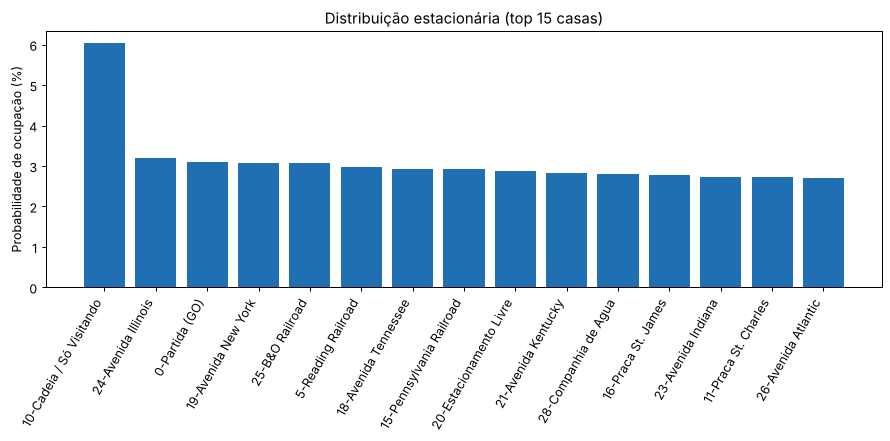

In [15]:
top15 = ranking[:15]
plt.figure(figsize=(10, 5))
plt.bar(range(15), [v_estacionario[i] * 100 for i in top15], color="#1f6fb2")
plt.xticks(range(15), [f"{i}-{NOMES[i]}" for i in top15], rotation=60, ha="right")
plt.ylabel("Probabilidade de ocupação (%)")
plt.title("Distribuição estacionária (top 15 casas)")
plt.tight_layout()
plt.show()

# Parte 5 - Extensão: Método da Potência Inversa

#### 5.1 Taxa de Mistura (Velocidade de Convergência)

O Método da Potência (Parte 3) só encontra o autovalor **dominante** ($\lambda = 1$).

Para estudar a velocidade de "mistura" do jogo (quão rápido o jogo esquece a posição inicial), precisamos do segundo maior autovalor em módulo, $\lambda_2$: o erro do método da potência decai proporcionalmente a $|\lambda_2/\lambda_1|^k$.

Obs: $\lambda_2$ e $\lambda_3$ formam um par complexo conjugado. Isso é típico de matrizes de transição "cíclicas" (o tabuleiro é percorrido sempre numa única direção), o que gera uma leve oscilação amortecida na convergência, além do decaimento exponencial puro. Por isso a Potência Inversa aqui usa aritmética **complexa** (um deslocamento real ficaria "preso" entre os dois autovalores conjugados).

Para encontrá-lo, usamos o **Método da Potência Inversa com deslocamento** (*shifted inverse power method*): encontra o autovalor de $A$ mais próximo de um deslocamento $\mu$, resolvendo repetidamente o sistema linear $(A - \mu I)\, w = v$ e normalizando $w$. O autovalor é reestimado a cada passo pelo quociente de Rayleigh (produto interno Hermitiano) $v^H A v \,/\, v^H v$.

In [16]:
lambda2_estimado = autovalores_ordenados[1]
mu = lambda2_estimado - 0.01  # deslocamento complexo, próximo de lambda_2
rng = np.random.default_rng(0)
v0_inv = rng.random(N) + 1j * rng.random(N)

lambda2_refinado, autovetor2, iters_inv = metodo_potencia_inversa(A, mu, v0_inv)
print(f"Convergiu em {iters_inv} iterações")
print(f"lambda_2 (Potência Inversa) = {lambda2_refinado.real:+.8f} {lambda2_refinado.imag:+.8f}j")
print(f"lambda_2 (numpy)            = {lambda2_estimado.real:+.8f} {lambda2_estimado.imag:+.8f}j")
print(f"Diferença absoluta          = {abs(lambda2_refinado - lambda2_estimado):.2e}")

Convergiu em 7 iterações
lambda_2 (Potência Inversa) = +0.37086302 +0.75146920j
lambda_2 (numpy)            = +0.37086302 +0.75146920j
Diferença absoluta          = 4.02e-14


O erro do Método da Potência decai aproximadamente como $(|\lambda_2|)^k$ a cada iteração $k$: a cada turno adicional simulado, o "resquício" da posição inicial encolhe por esse fator. Isso dá uma noção prática de quão rápido o Monopoly "esquece" onde os jogadores começaram e se estabiliza em torno do seu padrão de longo prazo.

|lambda_2 / lambda_1| = 0.838001
lances para reduzir a influência inicial a <1%: ~26.1


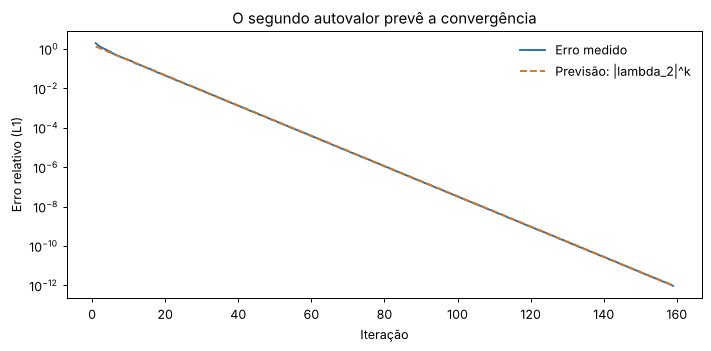

In [17]:
taxa = abs(lambda2_estimado)
print(f"|lambda_2 / lambda_1| = {taxa:.6f}")
print(f"lances para reduzir a influência inicial a <1%: ~{np.log(0.01) / np.log(taxa):.1f}")

k = np.arange(1, len(erros_go) + 1)
plt.figure(figsize=(8, 4))
plt.semilogy(k, erros_go, color="#1f6fb2", label="Erro medido")
plt.semilogy(k, erros_go[29] * taxa ** (k - 30.0), "--", color="#d9731a", label="Previsão: |lambda_2|^k")
plt.xlabel("Iteração")
plt.ylabel("Erro relativo (L1)")
plt.title("O segundo autovalor prevê a convergência")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# Parte 6 - Validação por Monte Carlo

Uma matriz bem construída ainda pode estar errada, e as hipóteses dela podem não representar o jogo. Por isso, duas perguntas separadas:

1. **A implementação está correta?** Simulamos exatamente as hipóteses da matriz. As frequências devem coincidir.
2. **As simplificações importam?** Simulamos as regras completas: novo lance em duplos, três duplos para a cadeia, baralhos reais sem reposição e duas políticas de cadeia (pagar e sair logo, ou tentar duplos por até três lances).

São 200 cadeias independentes de 20.000 lances cada, com 200 lances descartados no início.

Mesmas hipóteses da matriz     L1 vs. matriz = 0.0027   Cadeia =  6.05%   preso =  0.00%
Regras completas, paga e sai   L1 vs. matriz = 0.0050   Cadeia =  6.20%   preso =  3.94%
Regras completas, fica preso   L1 vs. matriz = 0.1099   Cadeia = 11.53%   preso =  9.38%


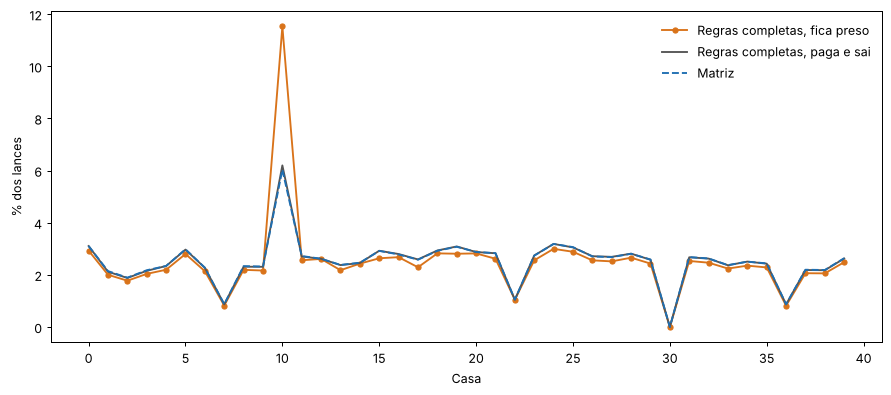

In [18]:
simplificado = simular("simplificado")
sair = simular("completo", "sair_logo")
ficar = simular("completo", "ficar")

for nome, r in [("Mesmas hipóteses da matriz", simplificado), ("Regras completas, paga e sai", sair), ("Regras completas, fica preso", ficar)]:
    print(f"{nome:<30} L1 vs. matriz = {np.abs(r.por_casa - v_estacionario).sum():.4f}   Cadeia = {r.por_casa[CADEIA]*100:5.2f}%   preso = {r.media[PRESO]*100:5.2f}%")

plt.figure(figsize=(10, 4.5))
plt.plot(ficar.por_casa * 100, marker="o", ms=4, color="#d9731a", label="Regras completas, fica preso")
plt.plot(sair.por_casa * 100, color="#555555", label="Regras completas, paga e sai")
plt.plot(v_estacionario * 100, "--", color="#1f6fb2", label="Matriz")
plt.xlabel("Casa")
plt.ylabel("% dos lances")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

A primeira linha confirma a implementação: a simulação com as mesmas hipóteses coincide com a matriz, dentro do ruído amostral. A segunda mostra que a matriz de 40 estados é uma ótima aproximação quando o jogador sai logo da cadeia. A terceira mostra seu ponto fraco: como a matriz não tem memória do tempo de prisão, ela subestima a Cadeia quando o jogador decide ficar.

O que muda na decisão? Refazendo a tabela de retorno com as frequências de quem fica preso:

In [19]:
for l in retorno_por_grupo(ficar.por_casa, "hotel")[:3]:
    print(f"{l['grupo']:<12} {l['lances_para_retorno']:.1f} lances")

Laranja      25.6 lances
Azul Claro   29.1 lances
Vermelho     33.6 lances


# Resultado Final

In [20]:
print(f"Número de estados: {N}")
print(f"Autovalor dominante: lambda_1 = {lambda1:.6f}")
print(f"Taxa de mistura: |lambda_2| = {abs(lambda2_estimado):.4f}")
print(f"Iterações do Método da Potência: {iters_go}")
print("\nTop 5 casas no longo prazo:")
for pos, i in enumerate(top5, start=1):
    print(f"  {pos}. {NOMES[i]} (casa {i}) - {v_estacionario[i]*100:.2f}%")
print(f"\nGrupo com retorno mais rápido (hotel): {retorno_por_grupo(v_estacionario, 'hotel')[0]['grupo']}")

Número de estados: 40
Autovalor dominante: lambda_1 = 1.000000
Taxa de mistura: |lambda_2| = 0.8380
Iterações do Método da Potência: 159

Top 5 casas no longo prazo:
  1. Cadeia / Só Visitando (casa 10) - 6.03%
  2. Avenida Illinois (casa 24) - 3.19%
  3. Partida (GO) (casa 0) - 3.11%
  4. Avenida New York (casa 19) - 3.08%
  5. B&O Railroad (casa 25) - 3.06%

Grupo com retorno mais rápido (hotel): Laranja
